# EN4554 Assignment 2 — Convolutional Neural Networks

**Name:** _your name_
**Index number:** _your index_
**GitHub repository:** _link_

**AI tool acknowledgement:** Claude (Anthropic) was used as a coding and learning assistant for this assignment. All code was reviewed, run, and understood by me.

## Setup

The CIFAR-10 training set is split into 45k training and 5k validation images. Each channel is normalised with the mean and std of the 45k training images only. Random seeds are fixed. The test set is not used until Task 4.

The data is small enough to keep on the GPU, so mini-batches are taken directly from GPU tensors.

In [2]:
import math, time, random
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import matplotlib.pyplot as plt

SEED = 0
def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed()
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('PyTorch', torch.__version__, '| device:', device,
      '|', torch.cuda.get_device_name(0) if device.type == 'cuda' else '')

PyTorch 2.6.0+cu124 | device: cuda | NVIDIA GeForce RTX 3090


In [3]:
train_full = torchvision.datasets.CIFAR10(root='./data', train=True, download=True)
classes = train_full.classes

# uint8 (50000, 32, 32, 3)  ->  float (50000, 3, 32, 32) in [0, 1]
X_all = torch.tensor(train_full.data).permute(0, 3, 1, 2).float() / 255.0
Y_all = torch.tensor(train_full.targets)

# Fixed 45k / 5k split
perm = torch.randperm(len(X_all), generator=torch.Generator().manual_seed(SEED))
train_idx, val_idx = perm[:45000], perm[45000:]

# Per-channel statistics from the TRAINING split only
mean = X_all[train_idx].mean(dim=(0, 2, 3), keepdim=True)
std  = X_all[train_idx].std(dim=(0, 2, 3), keepdim=True)

X_train = ((X_all[train_idx] - mean) / std).to(device)
Y_train = Y_all[train_idx].to(device)
X_val   = ((X_all[val_idx] - mean) / std).to(device)
Y_val   = Y_all[val_idx].to(device)

print('train:', tuple(X_train.shape), ' val:', tuple(X_val.shape))
print('channel mean:', mean.flatten().numpy().round(4))
print('channel std :', std.flatten().numpy().round(4))
print('normalised train mean/std per channel:',
      X_train.mean(dim=(0, 2, 3)).cpu().numpy().round(3), X_train.std(dim=(0, 2, 3)).cpu().numpy().round(3))

train: (45000, 3, 32, 32)  val: (5000, 3, 32, 32)
channel mean: [0.4912 0.482  0.4464]
channel std : [0.2472 0.2436 0.2617]
normalised train mean/std per channel: [0. 0. 0.] [1. 1. 1.]


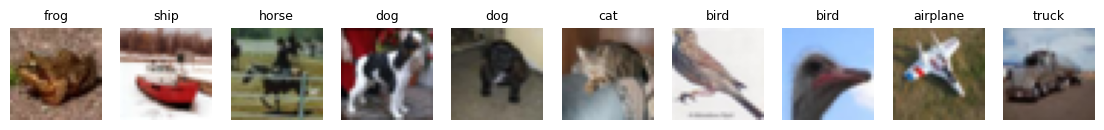

In [4]:
def batches(X, Y, batch_size, shuffle=True):
    idx = torch.randperm(len(X), device=X.device) if shuffle else torch.arange(len(X), device=X.device)
    for i in range(0, len(X), batch_size):
        j = idx[i:i + batch_size]
        yield X[j], Y[j]

# A few training images (un-normalised for display)
fig, axes = plt.subplots(1, 10, figsize=(14, 1.8))
for ax, i in zip(axes, range(10)):
    img = (X_train[i].cpu() * std[0] + mean[0]).permute(1, 2, 0).clamp(0, 1)
    ax.imshow(img); ax.set_title(classes[Y_train[i]], fontsize=9); ax.axis('off')
plt.show()

---
## Task 1: Backpropagation

### 1(a) Linear, ReLU and softmax cross-entropy with manual backward

Each layer saves what it needs in `forward`. In `backward` it receives the gradient of the loss with respect to its output and returns the gradient with respect to its input.

* **Linear** $Y = XW + b$, with $G = \partial L/\partial Y$: $\;\partial L/\partial W = X^\top G$, $\;\partial L/\partial b = \sum_n G_n$, $\;\partial L/\partial X = G W^\top$
* **ReLU** $y = \max(0, x)$: the gradient passes where $x > 0$ and is zero elsewhere.
* **Softmax cross-entropy** (mean over $N$ samples): $\partial L/\partial z = (p - \text{onehot}(y))/N$, where $p$ is the softmax output.

Weights use He initialisation, $\mathcal{N}(0, 2/d_\text{in})$.

In [5]:
class Linear:
    # y = x @ W + b    x: (N, d_in)   W: (d_in, d_out)   b: (d_out,)
    def __init__(self, d_in, d_out, std=None, dtype=torch.float32):
        std = math.sqrt(2.0 / d_in) if std is None else std   # He init by default
        self.W = torch.randn(d_in, d_out, device=device, dtype=dtype) * std
        self.b = torch.zeros(d_out, device=device, dtype=dtype)
        self.dW = torch.zeros_like(self.W)
        self.db = torch.zeros_like(self.b)

    def forward(self, x):
        self.x = x                       # cache the input for backward
        return x @ self.W + self.b

    def backward(self, dout):            # dout = dL/dy, shape (N, d_out)
        self.dW = self.x.T @ dout        # (d_in, N) @ (N, d_out) -> (d_in, d_out)
        self.db = dout.sum(dim=0)        # b is added to every row -> sum over the batch
        return dout @ self.W.T           # dL/dx, shape (N, d_in)

    def params(self): return [self.W, self.b]
    def grads(self):  return [self.dW, self.db]


class ReLU:
    def forward(self, x):
        self.mask = x > 0                # remember where the input was positive
        return x * self.mask

    def backward(self, dout):
        return dout * self.mask          # gradient flows only where x > 0

    def params(self): return []
    def grads(self):  return []


class SoftmaxCrossEntropy:
    def forward(self, logits, y):
        shifted = logits - logits.max(dim=1, keepdim=True).values      # avoids exp overflow
        log_probs = shifted - shifted.exp().sum(dim=1, keepdim=True).log()
        self.probs = log_probs.exp()
        self.y = y
        return -log_probs[torch.arange(len(y)), y].mean()

    def backward(self):
        N = len(self.y)
        dlogits = self.probs.clone()
        dlogits[torch.arange(N), self.y] -= 1                          # p - onehot(y)
        return dlogits / N                                             # /N because the loss is a mean


class MLP:
    # sizes = [3072, 256, 10] gives Linear(3072,256) -> act -> Linear(256,10)
    def __init__(self, sizes, activation=ReLU, std=None, dtype=torch.float32):
        self.layers = []
        for i in range(len(sizes) - 1):
            self.layers.append(Linear(sizes[i], sizes[i + 1], std=std, dtype=dtype))
            if i < len(sizes) - 2:                                     # no activation after the last layer
                self.layers.append(activation())
        self.loss_fn = SoftmaxCrossEntropy()

    def forward(self, x):
        for layer in self.layers:
            x = layer.forward(x)
        return x

    def loss(self, x, y):
        return self.loss_fn.forward(self.forward(x), y)

    def backward(self):
        dout = self.loss_fn.backward()
        for layer in reversed(self.layers):
            dout = layer.backward(dout)

    def params(self): return [p for layer in self.layers for p in layer.params()]
    def grads(self):  return [g for layer in self.layers for g in layer.grads()]

In [6]:
# Sanity check: one forward and backward pass on a small batch
set_seed()
mlp = MLP([3 * 32 * 32, 256, 128, 10])
xb, yb = X_train[:64].flatten(1), Y_train[:64]

loss = mlp.loss(xb, yb)
mlp.backward()
print(f'initial loss = {loss.item():.4f}   (ln 10 = {math.log(10):.4f})')
for i, (p, g) in enumerate(zip(mlp.params(), mlp.grads())):
    print(f'param {i}: shape {tuple(p.shape)!s:14}  grad shape {tuple(g.shape)!s:14}  grad norm {g.norm():.4f}')

initial loss = 2.9846   (ln 10 = 2.3026)
param 0: shape (3072, 256)     grad shape (3072, 256)     grad norm 8.1965
param 1: shape (256,)          grad shape (256,)          grad norm 0.1789
param 2: shape (256, 128)      grad shape (256, 128)      grad norm 2.6846
param 3: shape (128,)          grad shape (128,)          grad norm 0.1739
param 4: shape (128, 10)       grad shape (128, 10)       grad norm 2.0742
param 5: shape (10,)           grad shape (10,)           grad norm 0.1872


**Interpretation.** Every gradient has the same shape as its parameter, as required for the update $\theta \leftarrow \theta - \eta \nabla_\theta L$. The initial loss (≈ 2.98) is a little above $\ln 10 \approx 2.30$, the loss of a uniform guess over 10 classes. It is higher because the random initial weights already give slightly confident predictions.

### 1(b) Gradient check

Our gradients are compared with

1. **autograd**, by running the same network with PyTorch operations on copies of the same weights, and
2. **centred finite differences**, $\dfrac{L(\theta + h) - L(\theta - h)}{2h}$ with $h = 10^{-5}$, on 20 random entries of each parameter tensor.

Relative error $= \lVert a - b\rVert / (\lVert a\rVert + \lVert b\rVert)$. The check uses float64 so that rounding errors do not spoil the finite-difference estimate.

In [7]:
import pandas as pd

def rel_error(a, b):
    return ((a - b).norm() / (a.norm() + b.norm()).clamp_min(1e-12)).item()

def numerical_grad(net, x, y, p, i, h=1e-5):
    # centred difference for the i-th entry of parameter p
    flat = p.view(-1)
    old = flat[i].item()
    flat[i] = old + h; L_plus = net.loss(x, y).item()
    flat[i] = old - h; L_minus = net.loss(x, y).item()
    flat[i] = old
    return (L_plus - L_minus) / (2 * h)

set_seed()
gc_net = MLP([3 * 32 * 32, 64, 32, 10], dtype=torch.float64)
xg, yg = X_train[:16].flatten(1).double(), Y_train[:16]

# 1) manual backward
loss_manual = gc_net.loss(xg, yg)
gc_net.backward()
manual = [g.clone() for g in gc_net.grads()]

# 2) autograd on copies of the same parameters
params_ag = [p.clone().requires_grad_() for p in gc_net.params()]
h = xg
for i in range(0, len(params_ag), 2):
    h = h @ params_ag[i] + params_ag[i + 1]
    if i < len(params_ag) - 2:
        h = torch.relu(h)
loss_ag = F.cross_entropy(h, yg)
loss_ag.backward()
autograd = [p.grad for p in params_ag]
print(f'loss (ours) = {loss_manual.item():.12f}   loss (F.cross_entropy) = {loss_ag.item():.12f}')

# 3) centred finite differences on 20 random entries per tensor
rows = []
names = ['W1', 'b1', 'W2', 'b2', 'W3', 'b3']
for name, p, g_man, g_ag in zip(names, gc_net.params(), manual, autograd):
    idx = torch.randperm(p.numel())[:20]
    g_fd = torch.tensor([numerical_grad(gc_net, xg, yg, p, i) for i in idx.tolist()], dtype=torch.float64)
    g_man_s = g_man.view(-1)[idx].cpu()
    rows.append({
        'param': name, 'shape': tuple(p.shape),
        'rel. err vs autograd': rel_error(g_man, g_ag),
        'allclose (autograd)': torch.allclose(g_man, g_ag),
        'rel. err vs finite diff.': rel_error(g_man_s, g_fd),
        'allclose (finite diff.)': torch.allclose(g_man_s, g_fd, rtol=1e-5, atol=1e-7),
    })
pd.DataFrame(rows).style.format({'rel. err vs autograd': '{:.2e}', 'rel. err vs finite diff.': '{:.2e}'})

loss (ours) = 2.991249413305   loss (F.cross_entropy) = 2.991249413305


,param,shape,rel. err vs autograd,allclose (autograd),rel. err vs finite diff.,allclose (finite diff.)
0,W1,"(3072, 64)",6.45e-17,True,1.93e-10,True
1,b1,"(64,)",6.80e-17,True,2.68e-10,True
2,W2,"(64, 32)",4.31e-17,True,1.88e-10,True
3,b2,"(32,)",2.92e-17,True,1.10e-10,True
4,W3,"(32, 10)",6.15e-17,True,7.59e-11,True
5,b3,"(10,)",9.54e-17,True,8.94e-11,True


**Interpretation.** Our loss equals `F.cross_entropy` to all printed digits. Against autograd, the relative errors are about $10^{-17}$, which is float64 rounding, and `allclose` is `True` for every tensor, so the manual backward pass gives the same gradients as PyTorch. Against finite differences, the errors are about $10^{-10}$ and `allclose` is again `True`. This remaining error comes from the finite-difference approximation itself. Finite differences use no derivative formulas, so this agreement shows independently that the gradients are correct.

### 1(c) Training the MLP with SGD

Each 32×32×3 image is flattened to a 3072-vector. The MLP is 3072 → 512 → 256 → 10 with ReLU, trained with plain SGD ($\theta \leftarrow \theta - \eta\, \nabla_\theta L$) using our manual gradients. Settings: learning rate 0.01, batch size 128, 20 epochs.

epoch  1  train loss 1.591  val loss 1.713  train acc 0.445  val acc 0.397
epoch  2  train loss 1.453  val loss 1.619  train acc 0.495  val acc 0.430
epoch  3  train loss 1.374  val loss 1.584  train acc 0.527  val acc 0.449
epoch  4  train loss 1.298  val loss 1.541  train acc 0.555  val acc 0.464
epoch  5  train loss 1.250  val loss 1.531  train acc 0.572  val acc 0.472
epoch  6  train loss 1.205  val loss 1.531  train acc 0.584  val acc 0.472
epoch  7  train loss 1.130  val loss 1.487  train acc 0.621  val acc 0.488
epoch  8  train loss 1.093  val loss 1.482  train acc 0.630  val acc 0.494
epoch  9  train loss 1.050  val loss 1.475  train acc 0.648  val acc 0.493
epoch 10  train loss 1.017  val loss 1.481  train acc 0.657  val acc 0.496
epoch 11  train loss 0.972  val loss 1.468  train acc 0.680  val acc 0.500
epoch 12  train loss 0.929  val loss 1.474  train acc 0.696  val acc 0.497
epoch 13  train loss 0.905  val loss 1.485  train acc 0.703  val acc 0.501
epoch 14  train loss 0.86

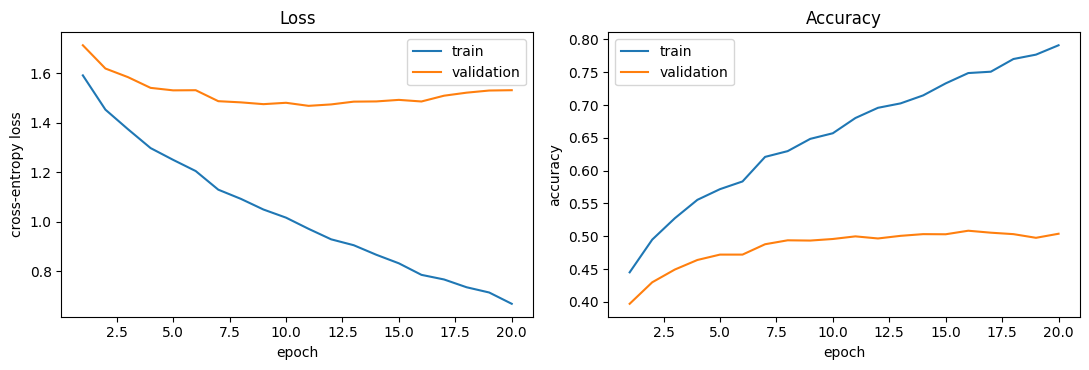

final validation accuracy: 0.5038   (best 0.5084 at epoch 16)


In [8]:
def sgd_step(net, lr):
    for p, g in zip(net.params(), net.grads()):
        p -= lr * g

def evaluate(net, X, Y, batch_size=1000):
    total_loss, correct = 0.0, 0
    for xb, yb in batches(X, Y, batch_size, shuffle=False):
        total_loss += net.loss(xb.flatten(1), yb).item() * len(yb)
        correct += (net.loss_fn.probs.argmax(dim=1) == yb).sum().item()
    return total_loss / len(X), correct / len(X)

set_seed()
mlp = MLP([3 * 32 * 32, 512, 256, 10])
lr, batch_size, epochs = 0.01, 128, 20

hist = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
for epoch in range(epochs):
    for xb, yb in batches(X_train, Y_train, batch_size):
        mlp.loss(xb.flatten(1), yb)
        mlp.backward()
        sgd_step(mlp, lr)
    tl, ta = evaluate(mlp, X_train, Y_train)
    vl, va = evaluate(mlp, X_val, Y_val)
    for k, v in zip(hist, (tl, vl, ta, va)):
        hist[k].append(v)
    print(f'epoch {epoch + 1:2d}  train loss {tl:.3f}  val loss {vl:.3f}  train acc {ta:.3f}  val acc {va:.3f}')

ep = range(1, epochs + 1)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.8))
ax1.plot(ep, hist['train_loss'], label='train'); ax1.plot(ep, hist['val_loss'], label='validation')
ax1.set_xlabel('epoch'); ax1.set_ylabel('cross-entropy loss'); ax1.set_title('Loss'); ax1.legend()
ax2.plot(ep, hist['train_acc'], label='train'); ax2.plot(ep, hist['val_acc'], label='validation')
ax2.set_xlabel('epoch'); ax2.set_ylabel('accuracy'); ax2.set_title('Accuracy'); ax2.legend()
plt.tight_layout(); plt.show()

print(f"final validation accuracy: {hist['val_acc'][-1]:.4f}   "
      f"(best {max(hist['val_acc']):.4f} at epoch {int(np.argmax(hist['val_acc'])) + 1})")

**Interpretation.** Training with our own gradients works: the training loss falls steadily from 1.59 to 0.67. The validation loss falls only until about epoch 11 (≈ 1.47) and then slowly rises, while training accuracy keeps climbing to 79%. The model has started to overfit, memorising the training images instead of learning patterns that generalise. Validation accuracy levels off at about **50%** (50.4% after 20 epochs, best 50.8% at epoch 16). This is far above the 10% of random guessing, but limited. Flattening the image throws away the spatial layout: the MLP treats every pixel as an unrelated input, so it must learn the same edge or shape separately at every position, using about 1.7M weights. This is the limitation that convolutional networks address in the later tasks.

### 1(d) Gradient norms in a 10-layer MLP: sigmoid vs ReLU

A 10-layer MLP (3072 → 256 → … → 256 → 10) is initialised twice, once with sigmoid and once with ReLU. Both use the same He initialisation, so the activation is the only difference. One forward and backward pass on 256 training images gives $\lVert \partial L / \partial W \rVert$ for each layer. Sigmoid's backward uses $\sigma'(x) = \sigma(x)(1 - \sigma(x))$.

Sigmoid  1.3e-04 1.8e-04 5.8e-04 1.9e-03 5.7e-03 2.0e-02 5.9e-02 1.8e-01 6.3e-01 1.9e+00
ReLU     6.0e+00 3.0e+00 4.0e+00 4.6e+00 5.4e+00 5.8e+00 6.7e+00 6.0e+00 6.6e+00 8.4e+00


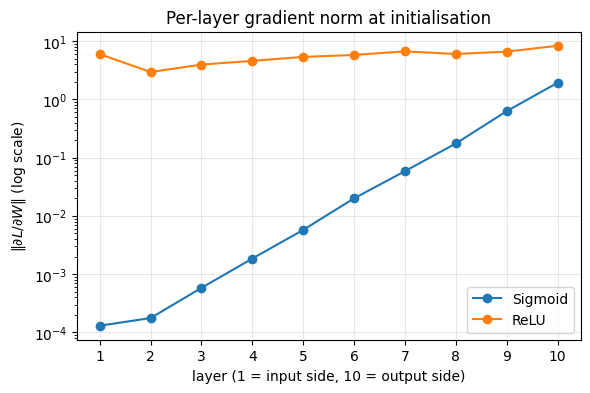

In [9]:
class Sigmoid:
    def forward(self, x):
        self.s = 1 / (1 + torch.exp(-x))
        return self.s

    def backward(self, dout):
        return dout * self.s * (1 - self.s)        # sigmoid'(x) = s(1 - s)

    def params(self): return []
    def grads(self):  return []

xb, yb = X_train[:256].flatten(1), Y_train[:256]
sizes = [3 * 32 * 32] + [256] * 9 + [10]           # 10 Linear layers

plt.figure(figsize=(6.5, 4))
for act in (Sigmoid, ReLU):
    set_seed()
    net = MLP(sizes, activation=act)
    net.loss(xb, yb)
    net.backward()
    norms = [layer.dW.norm().item() for layer in net.layers if isinstance(layer, Linear)]
    plt.semilogy(range(1, 11), norms, 'o-', label=act.__name__)
    print(f'{act.__name__:8s}', ' '.join(f'{n:.1e}' for n in norms))
plt.xlabel('layer (1 = input side, 10 = output side)')
plt.ylabel(r'$\|\partial L / \partial W\|$ (log scale)')
plt.title('Per-layer gradient norm at initialisation')
plt.xticks(range(1, 11)); plt.legend(); plt.grid(alpha=0.3)
plt.show()

**Interpretation.** With **sigmoid**, the gradient shrinks by about 3× at every layer going backwards. It is about 1.9 at the last layer but only about $10^{-4}$ at the first layer, roughly 15,000 times smaller (the straight line on the log plot means a constant shrink factor per layer). This is the **vanishing gradient** problem. Backpropagation multiplies the gradient by $\sigma'(x) = \sigma(x)(1-\sigma(x))$ at every layer, and $\sigma' \le 0.25$, so these factors compound over the depth. The early layers would therefore learn thousands of times more slowly than the later ones.

With **ReLU**, the gradient norm stays roughly constant across all ten layers (about 3–8). ReLU's derivative is exactly 1 for positive inputs, so it does not shrink the gradient. He initialisation ($\text{std} = \sqrt{2/d_\text{in}}$) is chosen to make up for ReLU zeroing about half the units, so the gradient scale is preserved from layer to layer. Layer 1 is slightly larger because it has 3072 inputs instead of 256, so its weight matrix has more entries. This is why ReLU replaced sigmoid in deep networks.